# VolGAN hedging vs Black–Scholes

This notebook reproduces the hedging experiment of Vuletić & Cont, *VolGAN: a generative model for arbitrage-free implied volatility surfaces* (Applied Mathematical Finance, 2025), Section 5, on AAPL options.

**The position.** Back-to-back one-month straddles (a call and a put struck at $K = 1.2\,S_0$, as in the paper's §5.5), 100 of each, held to expiry and rebalanced daily at the close. Options are marked off the real smoothed implied-vol surface with Black–Scholes at $r = 0$. Hedge trades pay half the bid/ask spread, measured from the Kaggle option quotes (the stock pays 1 bp).

**The hedges.**

| Method | Instruments | Hedge ratios |
|---|---|---|
| `unhedged` | none | reference |
| `bs_delta` | underlying | Black–Scholes delta (eq. 25) |
| `bs_delta_vega` | underlying + an ATM call with the straddle's expiry, re-struck when spot moves 2% | delta–vega neutral (eq. 26) |
| `volgan_delta` | underlying | regression across 1000 VolGAN next-day scenarios (eq. 27) |
| `volgan_atm` | underlying + the same ATM call | the same regression with both instruments |

The VolGAN hedge solves, for each day $t$,
$$\Delta V_t(\omega_j) = A_t + \sum_i \phi^i_t\,\Delta H^i_t(\omega_j) + \epsilon_j, \qquad j = 1,\dots,1000,$$
by least squares, where $\omega_j$ are joint (spot, surface) scenarios for the next day. Unlike Black–Scholes, the ratios pick up the model's view of how the surface moves *with* spot.

Each method trades in its own [yabte](https://github.com/bsdz/yabte) book, which is long the straddle and short the hedge, so the book's value is the tracking error $Z_t$. A smaller spread of $Z_t$ is a better hedge.

**Requirements.** Run from `notebooks/` with the `hedging` extra installed (`uv sync --extra hedging`). It needs `data-in/AAPL-prices.csv` and `data-out/surfaces_2016_2023.csv` (see the README; the surfaces are committed, the price CSV isn't) and the committed model `data-out/volgan_res.pkl`. It runs on CPU in a couple of minutes.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from VolGAN import load_results
from volgan_hedging import Market, VolGANScenarios, hedge_ratios, interp_iv
from hedging_backtest import metrics_frame, run_backtest, summarise, tracking_error
from transaction_costs import HalfSpreads

warnings.filterwarnings("ignore", category=UserWarning)  # torch / pandas noise
pd.set_option("display.float_format", "{:,.1f}".format)

MODEL = ROOT / "data-out/volgan_res.pkl"
PRICES = ROOT / "data-in/AAPL-prices.csv"
SURFACES = ROOT / "data-out/surfaces_2016_2023.csv"
SPREADS = ROOT / "data-out/option_half_spreads.csv"
for p in (MODEL, PRICES, SURFACES, SPREADS):
    assert p.exists(), f"missing {p}; see the README for how to build it"

results = load_results(MODEL, map_location="cpu")
market = Market(PRICES, SURFACES)
spreads = HalfSpreads.from_csv(SPREADS)  # measured half-spreads; stock 1 bp; yabte charges them
n_test = results.condition_test.shape[0]
test_dates = pd.DatetimeIndex(results.dates_t[-n_test:])
print(f"market data {market.dates[0].date()} to {market.dates[-1].date()}; "
      f"model trained up to {test_dates[0].date()} (test split {test_dates[0].date()} to {test_dates[-1].date()})")

VolGANData: dropped 10 surface dates with no matching price
VolGANData: dropped 10 surface dates with no matching price
market data 2016-01-04 to 2023-03-31; model trained up to 2020-04-03 (test split 2020-04-03 to 2020-12-31)


In [2]:
# One style for every chart: fixed colour per method (never by rank), and a
# line style that separates Black-Scholes (solid) from VolGAN (dashed) without colour.
STYLE = {
    "unhedged":      dict(color="#898781", ls=":",  label="unhedged"),
    "bs_delta":      dict(color="#2a78d6", ls="-",  label="BS delta"),
    "bs_delta_vega": dict(color="#eb6834", ls="-",  label="BS delta-vega"),
    "volgan_delta":  dict(color="#1baf7a", ls="--", label="VolGAN delta"),
    "volgan_atm":    dict(color="#6250d6", ls="--", label="VolGAN + ATM call"),
}
HEDGED = [m for m in STYLE if m != "unhedged"]
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.6, "axes.edgecolor": "#898781", "lines.linewidth": 2,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "date.converter": "concise",
})


def plot_by_roll(ax, series, rolls, style, lw=1.4):
    # Plot a daily series one roll at a time, so lines do not join across rolls.
    for i, r in enumerate(rolls):
        part = series[(series.index >= r.entry) & (series.index <= r.expiry)]
        ax.plot(part.index, part.values, lw=lw, **{**style, "label": style.get("label") if i == 0 else None})
    for r in rolls:
        ax.axvline(r.entry, color="#e4e3df", lw=0.8, zorder=0)

## 1. What VolGAN adds: joint spot–vol scenarios

Black–Scholes delta hedging treats the vol surface as fixed while spot moves. VolGAN instead simulates the next day's spot *and* surface together, conditioned on recent returns, realised vol and today's surface.

Below are 1000 scenarios for the day after 2020-09-02, the day before AAPL fell 8%. Each dot is one scenario's spot return and change in 30-day at-the-money implied vol. The cross marks what actually happened.

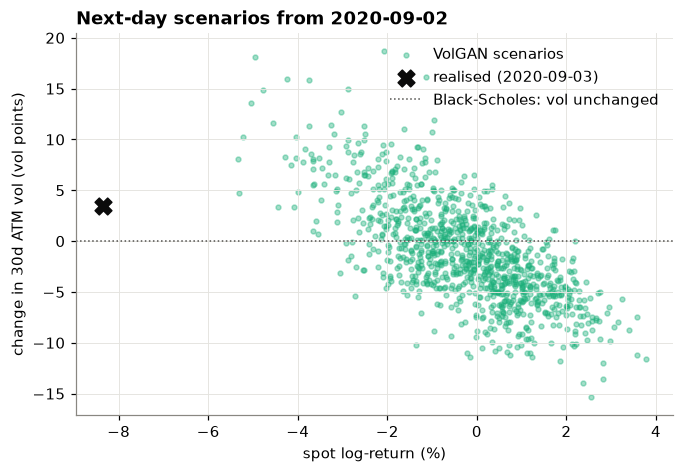

ATM vol 62.1%; scenario return std 1.53% (realised -8.34%); vol-on-return slope -2.26 vol points per 1% move


In [3]:
scen = VolGANScenarios(results, n_scenarios=1000, seed=0)
day = pd.Timestamp("2020-09-02")
nxt, spots, surfaces = scen.next_day(market, day)

S0 = market.spot.loc[day]
atm_vol = lambda S, surf: interp_iv(surf, 1.0, 30 / 365)  # 30-day ATM vol (K = S)
iv0 = atm_vol(S0, market.surfaces.loc[day].to_numpy())
ret = np.log(spots / S0) * 100
d_iv = (atm_vol(spots, surfaces) - iv0) * 100
real_ret = np.log(market.spot.loc[nxt] / S0) * 100
real_d_iv = (atm_vol(None, market.surfaces.loc[nxt].to_numpy()) - iv0) * 100

slope = np.polyfit(ret, d_iv, 1)[0]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(ret, d_iv, s=10, alpha=0.4, color=STYLE["volgan_delta"]["color"], label="VolGAN scenarios")
ax.scatter([real_ret], [real_d_iv], s=120, marker="X", color="#0b0b0b", label=f"realised ({nxt.date()})", zorder=3)
ax.axhline(0, color="#52514e", lw=1, ls=":", label="Black-Scholes: vol unchanged")
ax.set(xlabel="spot log-return (%)", ylabel="change in 30d ATM vol (vol points)",
       title=f"Next-day scenarios from {day.date()}")
ax.legend(frameon=False, loc="upper right")
plt.show()
print(f"ATM vol {iv0:.1%}; scenario return std {ret.std():.2f}% (realised {real_ret:.2f}%); "
      f"vol-on-return slope {slope:.2f} vol points per 1% move")

The negative slope is the leverage effect: the model expects implied vol to rise when spot falls. The regression hedge prices that in. The straddle is long vega, so a fall in spot raises its value twice: through delta, and through the vol rise that comes with it. Its effective delta is therefore more negative than the Black–Scholes delta. You can see this in the next chart, where VolGAN delta replicates with about 105 short shares at entry against Black–Scholes' 68.

Note that the spread of the scenarios is narrower than the realised move. This model under-disperses returns (a 90% scenario band covers about 63% of test days), which is one reason its hedges can misfire on large moves.

## 2. Hedge ratios over one straddle's life

Here are the hedge ratios each method sets each day for the straddle that covers that date. With $K = 1.2\,S_0$ the put is deep in the money, so the straddle behaves like about −100 shares and all the delta hedges converge there as expiry nears.

VolGAN + ATM call ends up close to Black–Scholes delta–vega. The ATM call absorbs the vol exposure, so the share holdings of the two-instrument hedges largely agree.

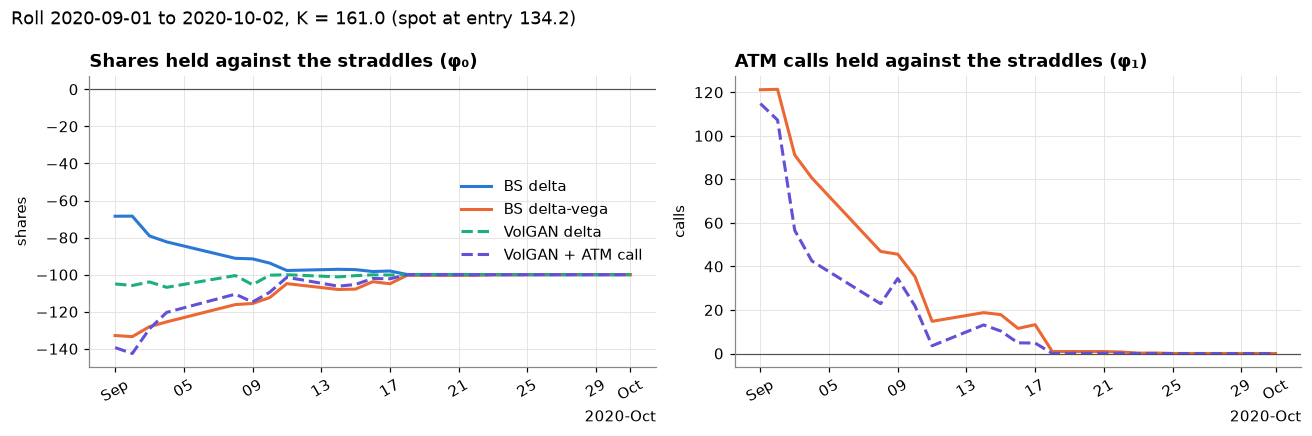

In [4]:
from volgan_hedging import make_rolls

roll = next(r for r in make_rolls(market, market.dates[market.dates >= "2020-08-01"][0], test_dates[-1], 21, 1.2)
            if r.entry <= day < r.expiry)
live = market.dates[(market.dates >= roll.entry) & (market.dates < roll.expiry)]
ratios = {m: pd.DataFrame([hedge_ratios(m, market, d, roll, 100, scen) for d in live], index=live)
          for m in HEDGED}

fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 4))
for m in HEDGED:
    a0.plot(ratios[m].index, ratios[m]["spot"], **STYLE[m])
for m in ("bs_delta_vega", "volgan_atm"):
    a1.plot(ratios[m].index, ratios[m]["hedge"], **STYLE[m])
a0.set(title="Shares held against the straddles (φ₀)", ylabel="shares")
a1.set(title="ATM calls held against the straddles (φ₁)", ylabel="calls")
for a in (a0, a1):
    a.axhline(0, color="#52514e", lw=0.8)
    a.tick_params(axis="x", rotation=30)
a0.legend(frameon=False)
fig.suptitle(f"Roll {roll.entry.date()} to {roll.expiry.date()}, K = {roll.call.strike:.1f} "
             f"(spot at entry {market.spot.loc[roll.entry]:.1f})", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 3. Backtest

`run_backtest` (from `hedging_backtest.py`) runs every method on back-to-back straddles in yabte.

Two periods:

- **2020 test split** (April to December 2020, 8 rolls): the last 15% of the training file, which the model never saw. It includes the post-COVID high-vol regime.
- **2021–2023** (26 rolls): surfaces built from the later Kaggle chains, fully out of sample.

All results are net of transaction costs. Only hedge trades pay: the stock pays 1 bp, and options pay half the median bid/ask spread quoted in the Kaggle chains for their moneyness and time to expiry (about 3 bp of spot at the money, 7–17 bp in the money). yabte charges them as the hedge trades (`run_backtest(..., spreads=...)`), so each book's value is already net of costs. The last table repeats the Z std without costs, the paper's set-up.

In [5]:
runs = {}
runs["2020 test split"] = run_backtest(results, market, spreads=spreads)
runs["2021-2023"] = run_backtest(results, market, start="2021-01-04", end="2023-03-31", spreads=spreads)

tables = {name: summarise(srr, rolls) for name, (srr, rolls, _) in runs.items()}
for name, t in tables.items():
    srr, rolls, _ = runs[name]
    print(f"\n{name}: {len(rolls)} rolls, {rolls[0].entry.date()} to {rolls[-1].expiry.date()}, net of costs")
    display(t.rename(columns={m: STYLE[m]["label"] for m in STYLE}))

# The same runs before costs (the paper's set-up): yabte's costs column added back
frictionless = pd.DataFrame({name: summarise(srr, rolls, net=False).loc["Z std"] for name, (srr, rolls, _) in runs.items()}).T
print("Z std without costs:")
display(frictionless.rename(columns={m: STYLE[m]["label"] for m in STYLE}))


2020 test split: 8 rolls, 2020-04-02 to 2020-12-04, net of costs


,unhedged,BS delta,BS delta-vega,VolGAN delta,VolGAN + ATM call
Z mean,-340.8,-28.9,-35.4,-65.2,-46.4
Z std,794.7,111.1,67.7,207.3,88.0
5% VaR,"1,391.2",281.0,136.7,637.0,265.3
2.5% VaR,"1,541.5",289.2,146.2,639.4,266.8
1% VaR,"1,836.1",292.0,168.1,639.4,266.8
daily dZ std,225.2,39.8,24.3,57.9,36.6
terminal Z_T std,"1,094.3",169.1,143.9,211.8,114.5
terminal |Z_T| mean,"1,258.7",155.1,102.8,139.6,102.3
hedge cost / roll,0.0,1.6,45.1,1.0,33.3



2021-2023: 26 rolls, 2021-01-04 to 2023-03-13, net of costs


,unhedged,BS delta,BS delta-vega,VolGAN delta,VolGAN + ATM call
Z mean,-41.1,-29.8,-23.1,-31.4,-29.6
Z std,929.5,51.7,54.1,38.5,28.0
5% VaR,"1,458.3",116.9,122.7,98.2,81.7
2.5% VaR,"1,699.2",141.4,146.2,98.8,87.8
1% VaR,"2,083.6",187.4,152.3,103.3,88.0
daily dZ std,279.7,19.4,14.9,20.5,12.0
terminal Z_T std,"1,191.6",63.5,59.5,28.3,27.4
terminal |Z_T| mean,985.9,61.0,47.6,55.3,45.3
hedge cost / roll,0.0,0.8,24.9,0.2,15.1


Z std without costs:


,unhedged,BS delta,BS delta-vega,VolGAN delta,VolGAN + ATM call
2020 test split,794.7,111.1,62.7,206.9,85.2
2021-2023,929.5,51.5,46.9,38.5,25.3


Rows: `Z std` and the VaRs pool $Z_t$ over every live day of every roll, as in the paper's Table 11. `daily dZ std` is the one-day P&L noise. `terminal Z_T std` is the spread of each roll's hedging error at expiry, the number a hedger ultimately cares about. `hedge cost / roll` is the average spread paid per straddle roll.

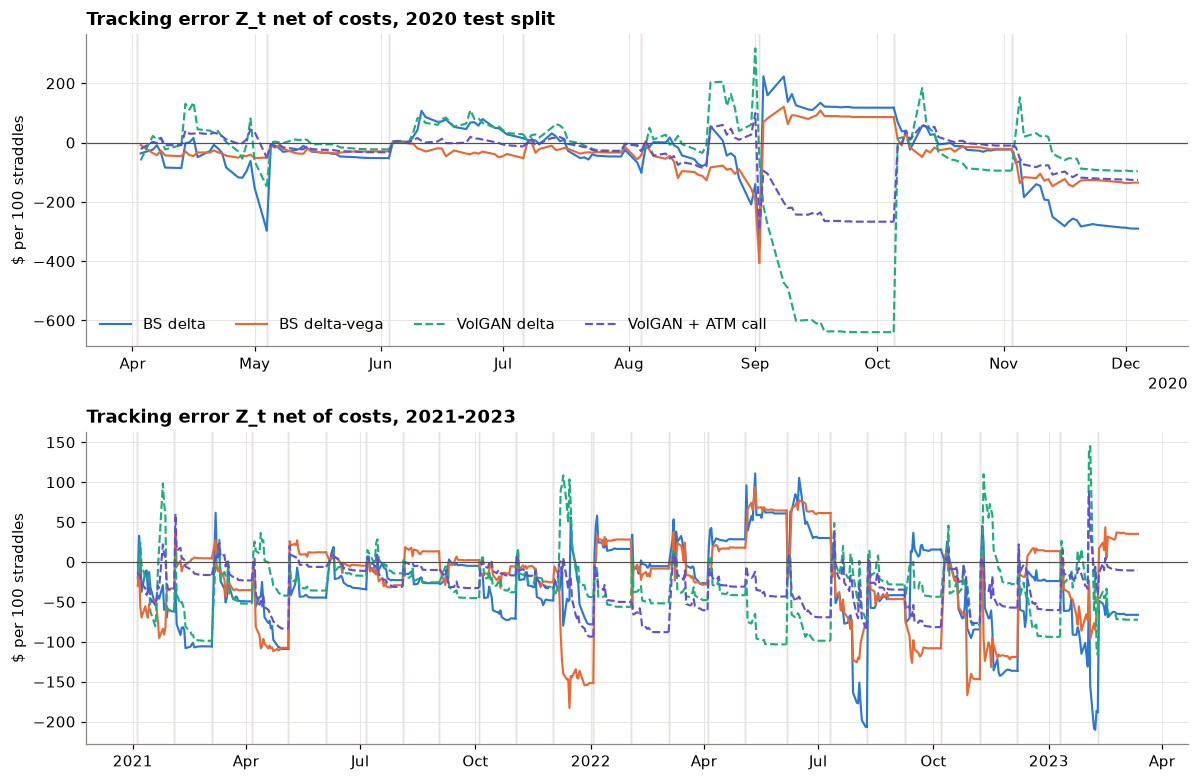

In [6]:
fig, axes = plt.subplots(len(runs), 1, figsize=(11, 3.6 * len(runs)))
for ax, (name, (srr, rolls, _)) in zip(axes, runs.items()):
    for m in HEDGED:  # Z resets to 0 at each roll's entry
        plot_by_roll(ax, tracking_error(srr, rolls, m), rolls, STYLE[m])
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set(title=f"Tracking error Z_t net of costs, {name}", ylabel="$ per 100 straddles")
axes[0].legend(frameon=False, ncol=4, loc="lower left")
plt.tight_layout(); plt.show()

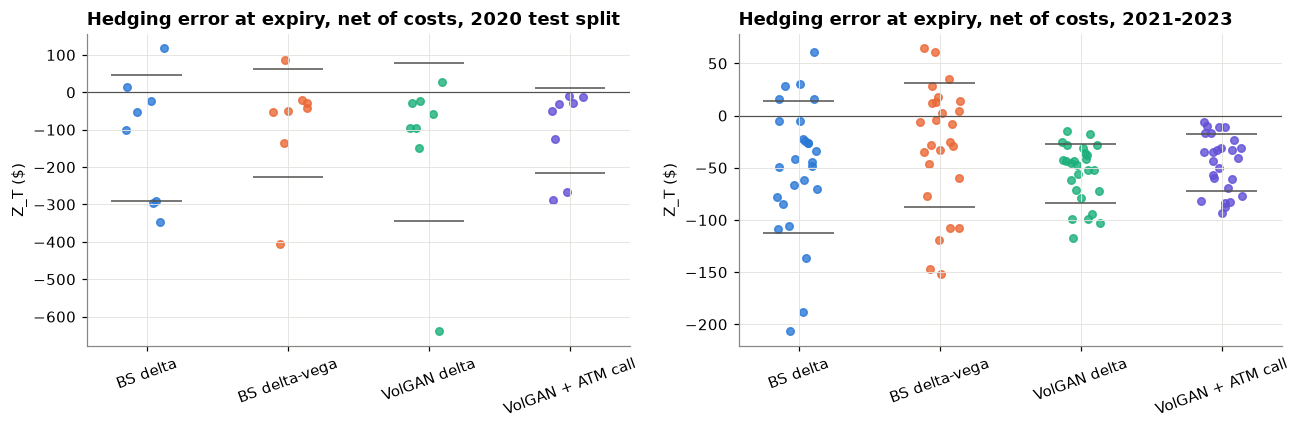

Each dot is one roll; the bars mark mean ± 1 std.


In [7]:
fig, axes = plt.subplots(1, len(runs), figsize=(12, 4), sharey=False)
for ax, (name, (srr, rolls, _)) in zip(axes, runs.items()):
    for i, m in enumerate(HEDGED):
        z = tracking_error(srr, rolls, m)
        zt = np.array([z.loc[r.expiry] for r in rolls if r.expiry in z.index])
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(zt))
        ax.scatter(i + jitter, zt, s=24, color=STYLE[m]["color"], alpha=0.8)
        ax.hlines([zt.mean() - zt.std(ddof=1), zt.mean() + zt.std(ddof=1)], i - 0.25, i + 0.25, color="#52514e", lw=1)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xticks(range(len(HEDGED)), [STYLE[m]["label"] for m in HEDGED], rotation=20)
    ax.set(title=f"Hedging error at expiry, net of costs, {name}", ylabel="Z_T ($)")
plt.tight_layout(); plt.show()
print("Each dot is one roll; the bars mark mean ± 1 std.")

## 4. Vol and greeks through the backtest

At every rebalance the strategy records metrics with yabte's `Strategy.record` (collected by `metrics_frame`, indexed by the close traded at). Each row holds:

- the implied vol of each option, read off that day's real surface at the option's own strike and maturity;
- Black–Scholes prices, deltas and vegas (vega per vol point);
- the hedge ratios $\phi_0, \phi_1$;
- the hedged book's **net** Black–Scholes delta and vega, i.e. what the hedge leaves open.

Every method sees the same vols and straddle greeks. Only the hedge ratios and net exposures differ.

In [8]:
metrics = {name: {m: metrics_frame(srr, m) for m in HEDGED} for name, (srr, rolls, _) in runs.items()}
cols = ["days_to_expiry", "spot", "iv_call", "iv_atm", "delta_straddle", "vega_straddle",
        "phi_spot", "phi_atm", "net_delta", "net_vega"]
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(metrics["2020 test split"]["volgan_atm"][cols].head())

,days_to_expiry,spot,iv_call,iv_atm,delta_straddle,vega_straddle,phi_spot,phi_atm,net_delta,net_vega
2020-04-02,32,61.233,0.500,0.549,-75.300,7.402,-126.022,79.802,8.237,1.649
2020-04-03,31,60.352,0.440,0.512,-85.814,4.771,-116.905,47.911,7.563,1.410
2020-04-06,28,65.618,0.412,0.477,-65.021,9.366,-119.646,97.021,3.559,2.347
2020-04-07,27,64.858,0.435,0.501,-68.052,8.575,-121.038,94.036,6.622,1.958
2020-04-08,26,66.517,0.409,0.452,-60.923,9.801,-119.341,92.722,5.680,3.332


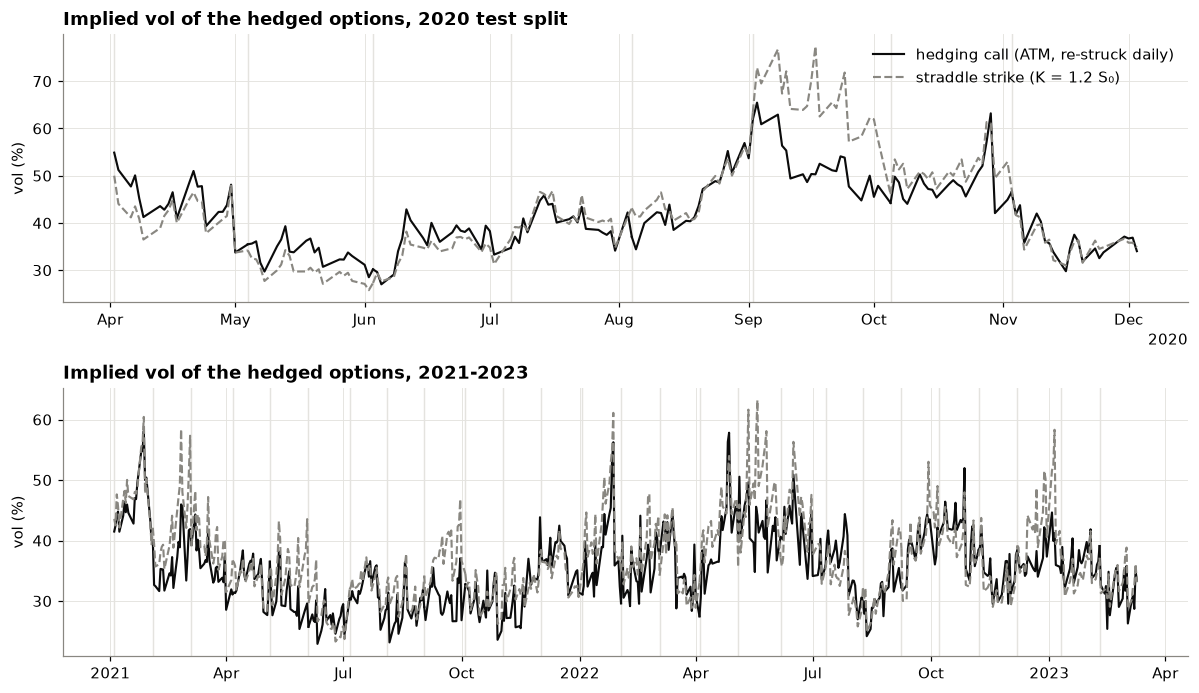

In [9]:
VOL_STYLE = {
    "iv_atm":  dict(color="#0b0b0b", ls="-",  label="hedging call (ATM, re-struck daily)"),
    "iv_call": dict(color="#898781", ls="--", label="straddle strike (K = 1.2 S₀)"),
}
fig, axes = plt.subplots(len(runs), 1, figsize=(11, 3.2 * len(runs)))
for ax, (name, (srr, rolls, _)) in zip(axes, runs.items()):
    met = metrics[name]["bs_delta"]  # vols are the same for every method
    for col, style in VOL_STYLE.items():
        plot_by_roll(ax, met[col] * 100, rolls, style)
    ax.set(title=f"Implied vol of the hedged options, {name}", ylabel="vol (%)")
axes[0].legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

The hedging call is re-struck at the money whenever spot moves more than 2% from its strike, so its vol stays close to the at-the-money vol for the straddle's remaining maturity. The straddle's strike is fixed for the roll, so its vol moves along the smile as spot moves. Both vols jump at roll boundaries, when the straddle's strike is reset and the maturity goes back to one month.

The straddle's own greeks are what every hedge has to offset:

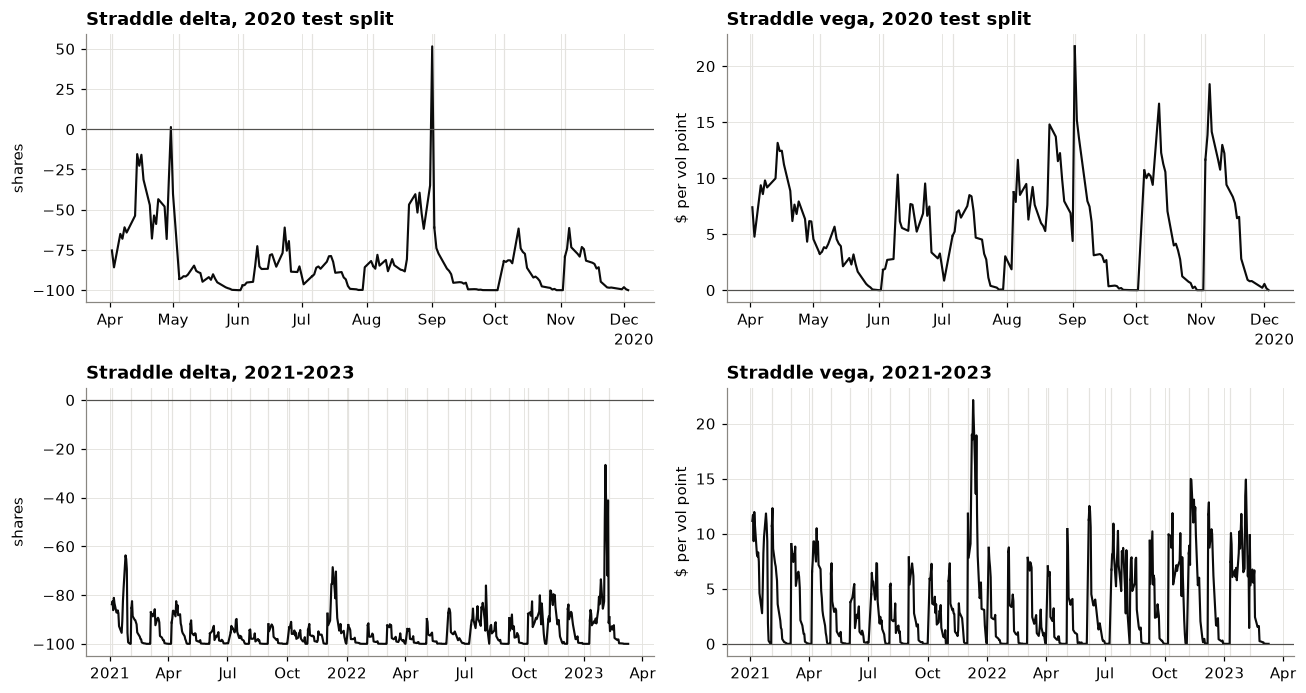

In [10]:
fig, axes = plt.subplots(len(runs), 2, figsize=(12, 3.2 * len(runs)))
for row, (name, (srr, rolls, _)) in zip(axes, runs.items()):
    met = metrics[name]["bs_delta"]
    plot_by_roll(row[0], met["delta_straddle"], rolls, dict(color="#0b0b0b", ls="-"))
    plot_by_roll(row[1], met["vega_straddle"], rolls, dict(color="#0b0b0b", ls="-"))
    row[0].set(title=f"Straddle delta, {name}", ylabel="shares")
    row[1].set(title=f"Straddle vega, {name}", ylabel="$ per vol point")
    for a in row:
        a.axhline(0, color="#52514e", lw=0.8)
plt.tight_layout(); plt.show()

### What each hedge leaves open

Net Black–Scholes exposures of each hedged book. By construction BS delta has zero net delta, and BS delta–vega has zero net delta and vega. The VolGAN hedges don't aim for zero Black–Scholes greeks: they hedge the joint spot–vol moves in the model's scenarios. Their net BS exposures show how far that view departs from Black–Scholes. (Neither delta-only hedge holds the ATM call, so BS delta and VolGAN delta have the same net vega, the straddle's own, and their lines overlap in the right-hand panels.)

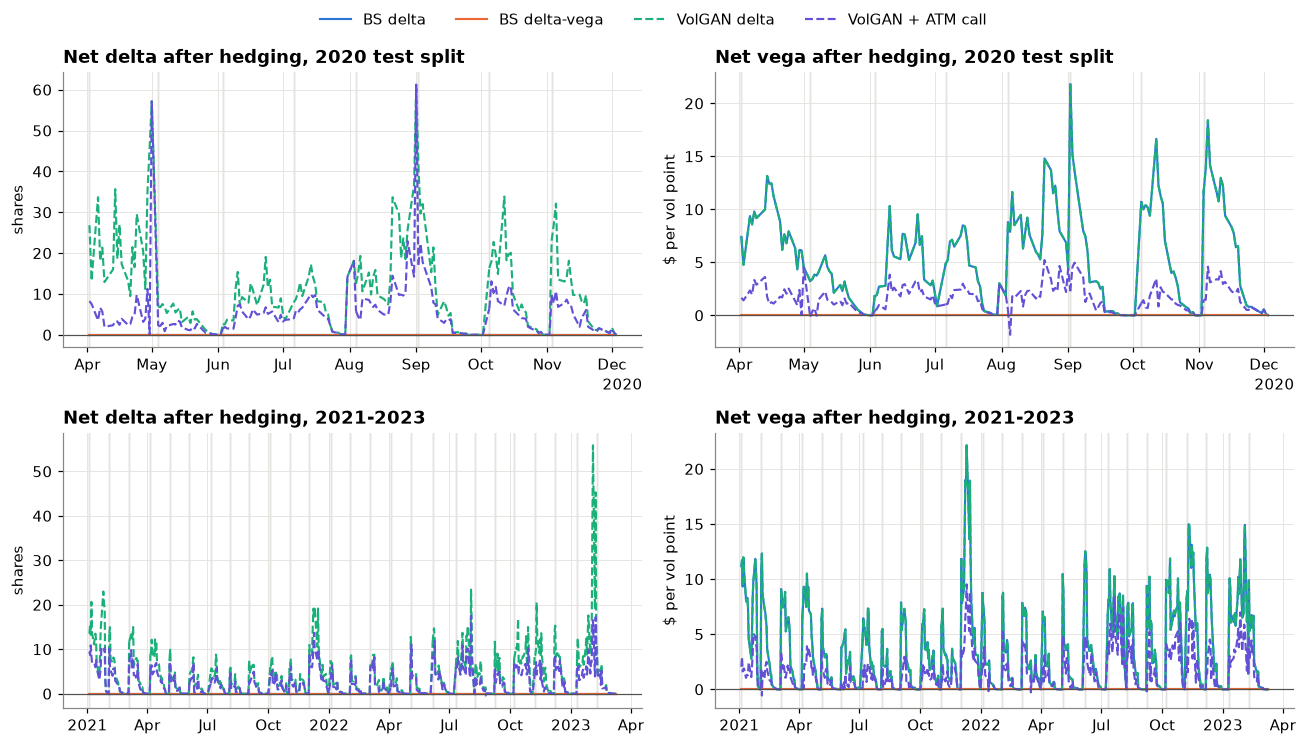

BS delta  BS delta-vega  \
2020 test split mean |net delta|                  0.0            0.0   
                mean |net vega|                   5.7            0.0   
                median |ATM calls|                0.0           65.1   
                max |ATM calls|                   0.0          200.0   
                days with |ATM calls| > 300       0.0            0.0   
2021-2023       mean |net delta|                  0.0            0.0   
                mean |net vega|                   3.7            0.0   
                median |ATM calls|                0.0           18.1   
                max |ATM calls|                   0.0          188.8   
                days with |ATM calls| > 300       0.0            0.0   

                                             VolGAN delta  VolGAN + ATM call  
2020 test split mean |net delta|                     11.7                5.7  
                mean |net vega|                       5.7                1.6  
                median |ATM calls|                    0.0               41.6  
                max |ATM calls|                       0.0              199.0  
                days with |ATM calls| > 300           0.0                0.0  
2021-2023       mean |net delta|                      4.5                2.8  
                mean |net vega|                       3.7                1.5  
                median |ATM calls|                    0.0                7.9  
                max |ATM calls|                       0.0              122.9  
                days with |ATM calls| > 300           0.0                0.0

In [11]:
fig, axes = plt.subplots(len(runs), 2, figsize=(12, 3.4 * len(runs)))
for row, (name, (srr, rolls, _)) in zip(axes, runs.items()):
    for m in HEDGED:
        plot_by_roll(row[0], metrics[name][m]["net_delta"], rolls, STYLE[m])
        plot_by_roll(row[1], metrics[name][m]["net_vega"], rolls, STYLE[m])
    row[0].set(title=f"Net delta after hedging, {name}", ylabel="shares")
    row[1].set(title=f"Net vega after hedging, {name}", ylabel="$ per vol point")
    for a in row:
        a.axhline(0, color="#52514e", lw=0.8)
fig.legend(*axes[0][0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

stats = {
    "mean |net delta|": lambda f: f.net_delta.abs().mean(),
    "mean |net vega|": lambda f: f.net_vega.abs().mean(),
    "median |ATM calls|": lambda f: f.phi_atm.abs().median(),
    "max |ATM calls|": lambda f: f.phi_atm.abs().max(),
    "days with |ATM calls| > 300": lambda f: (f.phi_atm.abs() > 300).sum(),
}
summary = pd.concat({
    name: pd.DataFrame({STYLE[m]["label"]: {k: fn(metrics[name][m]) for k, fn in stats.items()} for m in HEDGED})
    for name in metrics
})
display(summary)

**Reading the net exposures.**

- The VolGAN-hedged books are net *long* Black–Scholes delta almost every day. The replicating position $\phi_0$ is more negative than the straddle's BS delta, so the hedger, who holds $-\phi_0$ shares, *buys* more stock than $-\Delta_{\text{straddle}}$. That is the leverage effect from section 1: a fall in spot comes with a rise in vol, so the straddle's effective delta is more negative than its BS delta.
- VolGAN + ATM call leaves part of the straddle's BS vega unhedged: about 30% in 2020 and 40% in 2021–23 (compare its mean |net vega| with BS delta's, which is the straddle's full vega). It buys fewer ATM calls than BS delta–vega because in the model's scenarios short-dated vol moves are partly explained by spot.
- No hedge needs more than 2 ATM calls per straddle (max |ATM calls| ≤ 200 for 100 straddles), because the hedging call is kept within 2% of the money. The next section shows what happens otherwise.

### How the hedging call is struck, and what it costs

There are three ways to choose the hedging call:

- **Struck once at entry and held** (`hedge_strike="entry"`). Once spot moves away from the entry level, the call is deep in or out of the money and has almost no vega. In the last week of a roll it can have almost none, so matching the straddle's vega takes enormous positions: hundreds of millions of calls for BS delta–vega, offset by an equally huge stock position. Without costs the P&L survives, because the two nearly cancel. With costs the hedge is ruinous.
- **Re-struck at the money every day** (`restrike_band=0`). This keeps the hedge small (at most 2 calls per straddle), but it sells yesterday's call and buys today's every day, paying the spread each time.
- **Re-struck when spot moves 2% from the strike** (the default). The call stays near the money, so the hedge stays small, and it is replaced only every few days. That roughly halves the cost of daily re-striking.

The 2% band was picked because it is better for the Black–Scholes benchmark than a 5% band is, not tuned for VolGAN. `max_hedge_ratio` (calls per straddle, off by default) is an extra safety net, with a delta-only fallback.

In [12]:
# Re-run both periods with the other two ways of striking the hedging call
PERIODS = [("2020 test split", {}), ("2021-2023", dict(start="2021-01-04", end="2023-03-31"))]
variants = {"2% band (default)": runs}
variants["re-struck daily"] = {n: run_backtest(results, market, restrike_band=0.0, spreads=spreads, **kw) for n, kw in PERIODS}
variants["struck at entry"] = {n: run_backtest(results, market, hedge_strike="entry", spreads=spreads, **kw) for n, kw in PERIODS}
rows = {}
for name, _ in PERIODS:
    for label, vr in variants.items():
        srr, rolls, _ = vr[name]
        free = summarise(srr, rolls, net=False)
        net = summarise(srr, rolls)
        for m in ("bs_delta_vega", "volgan_atm"):
            rows[(name, label, STYLE[m]["label"])] = {
                "Z std, no costs": free.loc["Z std", m], "Z std, costs": net.loc["Z std", m],
                "mean |Z_T|, costs": net.loc["terminal |Z_T| mean", m],
                "cost / roll": net.loc["hedge cost / roll", m],
                "max |calls|": metrics_frame(srr, m).phi_atm.abs().max()}
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(pd.DataFrame(rows).T)

Z std, no costs  \
2020 test split 2% band (default) BS delta-vega                 62.7   
                                  VolGAN + ATM call             85.2   
                re-struck daily   BS delta-vega                 61.2   
                                  VolGAN + ATM call             84.6   
                struck at entry   BS delta-vega                 69.9   
                                  VolGAN + ATM call             76.3   
2021-2023       2% band (default) BS delta-vega                 46.9   
                                  VolGAN + ATM call             25.3   
                re-struck daily   BS delta-vega                 46.9   
                                  VolGAN + ATM call             24.7   
                struck at entry   BS delta-vega                 46.1   
                                  VolGAN + ATM call             28.8   

                                                     Z std, costs  \
2020 test split 2% band (default) BS delta-vega              67.7   
                                  VolGAN + ATM call          88.0   
                re-struck daily   BS delta-vega              76.3   
                                  VolGAN + ATM call          86.9   
                struck at entry   BS delta-vega       4,613,116.0   
                                  VolGAN + ATM call         289.0   
2021-2023       2% band (default) BS delta-vega              54.1   
                                  VolGAN + ATM call          28.0   
                re-struck daily   BS delta-vega              62.1   
                                  VolGAN + ATM call          30.3   
                struck at entry   BS delta-vega       1,828,756.1   
                                  VolGAN + ATM call      11,251.9   

                                                     mean |Z_T|, costs  \
2020 test split 2% band (default) BS delta-vega                  102.8   
                                  VolGAN + ATM call              102.3   
                re-struck daily   BS delta-vega                  143.6   
                                  VolGAN + ATM call              130.1   
                struck at entry   BS delta-vega           10,082,631.7   
                                  VolGAN + ATM call              523.6   
2021-2023       2% band (default) BS delta-vega                   47.6   
                                  VolGAN + ATM call               45.3   
                re-struck daily   BS delta-vega                   63.6   
                                  VolGAN + ATM call               60.3   
                struck at entry   BS delta-vega            2,168,382.8   
                                  VolGAN + ATM call            9,080.8   

                                                     cost / roll   max |calls|  
2020 test split 2% band (default) BS delta-vega             45.1         200.0  
                                  VolGAN + ATM call         33.3         199.0  
                re-struck daily   BS delta-vega             82.4         200.0  
                                  VolGAN + ATM call         60.3         199.0  
                struck at entry   BS delta-vega     10,082,551.9 315,196,424.1  
                                  VolGAN + ATM call        474.8      10,658.1  
2021-2023       2% band (default) BS delta-vega             24.9         188.8  
                                  VolGAN + ATM call         15.1         122.9  
                re-struck daily   BS delta-vega             51.4         188.8  
                                  VolGAN + ATM call         30.7         122.9  
                struck at entry   BS delta-vega      2,168,360.5 205,321,721.7  
                                  VolGAN + ATM call      9,039.9     633,695.0

## 5. How much does the seed matter?

GAN training is noisy. The README's seed study trained three models (seeds 0–2) with identical settings; the committed model is seed 2. If those models are present in `data-out/seeds/` (they aren't committed, so retrain with `python volgan_cli.py --train --seed N --output-path data-out/seeds/seedN.pkl` to recreate them), the cell below re-runs the out-of-sample backtest for each, net of costs.

In [13]:
seed_paths = sorted((ROOT / "data-out/seeds").glob("seed[0-9].pkl"))
if not seed_paths:
    print("No seed models found; skipping. README numbers, net of costs: VolGAN + ATM call Z std "
          "66 / 31 / 28 (seeds 0/1/2) vs BS delta-vega 54 on 2021-2023.")
else:
    rows = {}
    for p in seed_paths:
        srr, rolls, _ = run_backtest(load_results(p), market, start="2021-01-04", end="2023-03-31", spreads=spreads)
        t = summarise(srr, rolls)
        rows[p.stem] = t.loc[["Z std", "terminal |Z_T| mean"]].stack()
    with pd.option_context("display.float_format", "{:,.1f}".format):
        display(pd.DataFrame(rows).T.rename(columns=lambda c: STYLE.get(c, {}).get("label", c), level=1))

Z std                                                        \
      unhedged BS delta BS delta-vega VolGAN delta VolGAN + ATM call   
seed0    929.5     51.7          54.1         76.7              65.6   
seed1    929.5     51.7          54.1         34.6              31.1   
seed2    929.5     51.7          54.1         38.5              28.0   

      terminal |Z_T| mean                                      \
                 unhedged BS delta BS delta-vega VolGAN delta   
seed0               985.9     61.0          47.6         64.0   
seed1               985.9     61.0          47.6         52.6   
seed2               985.9     61.0          47.6         55.3   

                         
      VolGAN + ATM call  
seed0              56.1  
seed1              45.2  
seed2              45.3

## Takeaways

- Every hedge removes most of the straddle's risk. Hedging with the underlying alone cuts the tracking-error spread by roughly 75–95%.
- **Out of sample (2021–2023), net of costs**, the committed model's VolGAN + ATM call hedge has about half the spread of Black–Scholes delta–vega. Pooled $Z_t$ std is 28 against 54, and std at expiry 27 against 59; the daily std and the VaRs are also lower. Mean absolute error at expiry is close, though: 45 against 48. VolGAN delta beats Black–Scholes delta on pooled std (39 against 52), std at expiry (28 against 64), the VaRs and mean absolute error at expiry (55 against 61), but not on daily std (20.5 against 19.4).
- **Costs matter for the option hedges.** In 2021–23, BS delta–vega paid about 25 per roll and VolGAN + ATM call 15, because VolGAN buys fewer hedging calls. The delta-only hedges paid under 1. After costs, BS delta–vega is no better than plain BS delta on Z std (54 against 52), while VolGAN + ATM call keeps most of its advantage (25 without costs, 28 with).
- **Errors at expiry are biased negative for every hedge that leaves vega open.** This is the variance risk premium. Implied vol at the straddle's strike averaged 36% at entry against 30% realised (43% against 37% in 2020), so a long straddle loses theta faster than it earns gamma. With $r = 0$, Black–Scholes theta is proportional to vega, so a hedge that cancels the vega also cancels most of the theta. Without costs, mean $Z_T$ in 2021–23 was BS delta −49, VolGAN delta −55, VolGAN + ATM call −30 and BS delta–vega −3. Costs add a further negative drift to the two option hedges.
- **In the 2020 test split**, BS delta–vega is best on pooled $Z_t$ (68 against 88 for VolGAN + ATM call). VolGAN + ATM call has the smaller spread at expiry (114 against 144), and their mean absolute errors at expiry are the same (102 and 103). The VolGAN delta hedge lost about 600 on the September 2020 roll, which opened the day before AAPL's 8% fall, a move far outside its scenarios (section 1).
- **The result depends on the training seed** (section 5). Net of costs, two of the three trained models beat Black–Scholes on spread out of sample, and one (seed 0) does not. With 8 and 26 rolls the samples are also small. Treat this as evidence that the scenario-regression hedge *can* beat Black–Scholes, not that it reliably does.

Caveats: $r = 0$, spot used as the forward, and option marks come from smoothed Kaggle data rather than traded prices. Costs use the median quoted half-spread, with no market impact for larger trades and no execution inside the spread.